# AI Futures Model playground

This is the same model that serves [aifuturesmodel.com](https://www.aifuturesmodel.com/) (`AI-Futures-Project/aifm-public` @ `1c40ecd`).
`aifm.run()` sends a request to the website's own `/api/compute` handler in-process. Responses were checked against the live site and are identical to ~1e-9 years.

Parameters use **API units**. For example, `ac_time_horizon_minutes` is in minutes, not the slider's log10 value. See `aifm.params()` for the full list.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # repo root
import playground.aifm as aifm
import matplotlib.pyplot as plt
aifm.list_presets()

,id,label
0,daniel-08-16-26,Daniel's median parameters (08/16/26)
1,eli-08-16-26,Eli's median parameters (08/16/26)
2,brendan-08-16-26,Brendan's median parameters (08/16/26)
3,daniel-04-02-26,Daniel's median parameters (04/02/26)
4,daniel-12-29-25,Daniel's median parameters (12/29/25)
5,eli-04-02-26,Eli's median parameters (04/02/26)
6,eli-12-29-25,Eli's median parameters (12/29/25)
7,ai2027-handcrafted,Example trajectory similar to AI 2027 (handcra...


## 1. The homepage forecast (Daniel's median parameters)

In [2]:
base = aifm.run(label='Daniel 08/16/26')
base

Run(Daniel 08/16/26: AC=2027-10, AI2027=2028-05, SAR=2028-05, TED=2028-08, SIAR=2028-10, ASI=2028-12)

In [3]:
base.milestones[['date', 'year', 'effective_compute_ooms']]

,date,year,effective_compute_ooms
milestone,,,
AC,2027-10,2027.787079,30.494522
AI2027-SC,2028-05,2028.408610,32.306485
AIR-10000x,2029-02,2029.106742,39.839425
AIR-2000x,2028-12,2028.944649,37.393655
AIR-250x,2028-09,2028.746581,34.804903
AIR-25x,2028-06,2028.442985,32.485635
AIR-5x,2028-01,2028.061323,31.114693
ASI,2028-12,2028.928420,37.113925
Maximum possible experiment selection skill,not reached,NaN,NaN


In [4]:
# Every parameter the website sends (API units)
pd_params = __import__('pandas').Series(aifm.params(), name='value'); pd_params

taste_schedule_type                                       SDs per progress-year
present_doubling_time                                                   0.33284
ac_time_horizon_minutes                                                120000.0
doubling_difficulty_growth_factor                                          0.92
rho_coding_labor                                                             -2
rho_experiment_capacity                                                  -0.155
alpha_experiment_capacity                                                 0.809
direct_input_exp_cap_ces_params                                           False
r_software                                                                  2.4
software_progress_rate_at_reference_year                                      1
coding_labor_normalization                                                    1
experiment_compute_exponent                                               0.655
automation_fraction_at_coding_automation

## 2. Compare forecasters

In [5]:
runs = [base, aifm.run('eli-08-16-26', label='Eli'), aifm.run('brendan-08-16-26', label='Brendan'),
        aifm.run('ai2027-handcrafted', label='AI-2027-like')]
aifm.compare(*runs)

,Daniel 08/16/26,Eli,Brendan,AI-2027-like
AC,2027-10,2028-05,2028-01,2027-10
AI2027-SC,2028-05,2029-01,2028-08,2028-05
SAR-level-experiment-selection-skill,2028-05,2029-02,2028-07,2028-05
TED-AI,2028-08,2029-10,2028-12,2028-08
SIAR-level-experiment-selection-skill,2028-10,2030-01,2029-01,2028-10
ASI,2028-12,2030-11,2029-04,2028-12


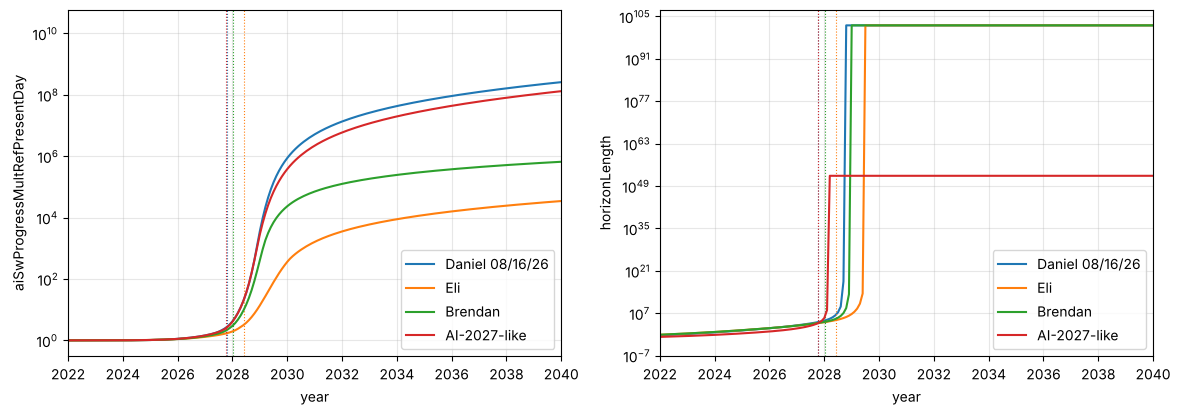

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
aifm.plot(*runs, column='aiSwProgressMultRefPresentDay', logy=True, ax=axes[0])
aifm.plot(*runs, column='horizonLength', logy=True, ax=axes[1]);

## 3. Change parameters

These are the four **Key Parameters** sliders on the homepage:
* `serial_uplift_at_reference_date`: serial coding uplift as of Aug 2026 (2×)
* `excess_uplift_doubling_time`: months for (uplift − 1) to double (5)
* `median_to_top_taste_multiplier`: top/median researcher value ratio (3.97)
* `ai_research_taste_slope`: how quickly AIs improve at research taste (3 SD per progress-year)

In [7]:
slow = aifm.run(excess_uplift_doubling_time=10, ai_research_taste_slope=1.5, label='slower uplift & taste')
aifm.compare(base, slow)

,Daniel 08/16/26,slower uplift & taste
AC,2027-10,2029-03
AI2027-SC,2028-05,2029-12
SAR-level-experiment-selection-skill,2028-05,2030-08
TED-AI,2028-08,2031-09
SIAR-level-experiment-selection-skill,2028-10,2033-03
ASI,2028-12,2035-03


,AC,SAR-level-experiment-selection-skill,ASI
excess_uplift_doubling_time,,,
2.5,2027.160638,2027.744827,2028.249021
3.5,2027.407131,2027.987844,2028.512949
5.0,2027.787079,2028.375600,2028.928420
7.0,2028.318197,2028.931878,2029.542044
10.0,2029.193618,2029.910530,2030.664523
14.0,2030.691819,2031.605749,2032.549832
20.0,2033.775674,2034.944421,2036.096988


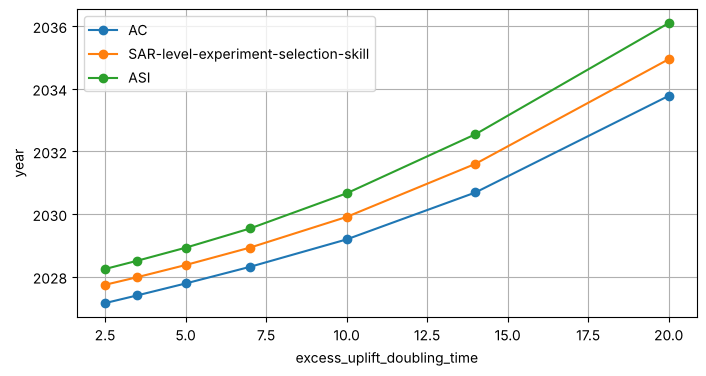

In [8]:
sw = aifm.sweep('excess_uplift_doubling_time', [2.5, 3.5, 5, 7, 10, 14, 20])
ax = sw.plot(marker='o', figsize=(8, 4), grid=True); ax.set_ylabel('year'); sw

## 4. Compute scenarios and AC anchor modes
The UI's compute-growth knobs are disabled upstream: `time_series.py` returns the base CSV, and the live site does the same.
To model a compute slowdown, edit the input series instead with `aifm.compute_scenario()`, which does what the site's CSV editor does.

In [9]:
half = aifm.run(custom_time_series=aifm.compute_scenario(after=2027, growth_multiplier=0.5),
               label='compute growth halves after 2027')
frozen = aifm.run(custom_time_series=aifm.compute_scenario(after=2027, growth_multiplier=0.0),
                  label='compute frozen at 2027')
th = aifm.run(ac_anchor_mode='time-horizon', label='AC via METR horizon (1 work-year)')
rev = aifm.run(ac_anchor_mode='revenue', label='AC via revenue')
aifm.compare(base, half, frozen, th, rev)

/home/user/pdoomvideo/_ext/aifm-public/progress_model/metrics_computation.py:389: RuntimeWarning: invalid value encountered in divide
  logmean = np.where(np.abs(lb - la) < 1e-9, np.sqrt(a * b), (b - a) / (lb - la))


,Daniel 08/16/26,compute growth halves after 2027,compute frozen at 2027,AC via METR horizon (1 work-year),AC via revenue
AC,2027-10,2027-12,2028-02,2028-05,2028-02
AI2027-SC,2028-05,2028-10,2029-09,2029-01,2028-10
SAR-level-experiment-selection-skill,2028-05,2028-10,2029-08,2029-01,2028-10
TED-AI,2028-08,2029-03,2030-06,2029-04,2029-01
SIAR-level-experiment-selection-skill,2028-10,2029-06,2031-02,2029-06,2029-03
ASI,2028-12,2029-08,2031-08,2029-08,2029-05


## 5. Trajectory columns & model internals

In [10]:
base.series.columns.tolist()

['aiCodingLaborMultRefPresentDay',
 'aiCodingLaborMultiplier',
 'aiResearchTaste',
 'aiSwProgressMultRefPresentDay',
 'automationFraction',
 'capabilityEci',
 'capabilityEciRate',
 'commercialComputeH100e',
 'companyShareOfWorldPct',
 'companyShareOfWorldPctTotal',
 'effectiveCompute',
 'etsp',
 'etspRate',
 'excessSerialCodingLaborUplift',
 'experimentCapacity',
 'experimentCompute',
 'horizonLength',
 'humanLabor',
 'inferenceCompute',
 'predictedRevenue',
 'progress',
 'progressRate',
 'researchEffort',
 'researchStock',
 'serialCodingLaborMultiplier',
 'softwareEfficiency',
 'softwareProgressRate',
 'spendPctCommercial',
 'spendPctCumCommercial',
 'spendPctCumExperiment',
 'spendPctCumInference',
 'spendPctCumTraining',
 'spendPctExperiment',
 'spendPctInference',
 'spendPctTraining',
 'totalAiCompanyComputeH100e',
 'totalRdComputeH100e',
 'trainingCompute',
 'trainingComputeH100e',
 'trainingSystemPerformance',
 'trainingSystemPerformanceGrowthRate',
 'worldComputeH100e']

In [11]:
m = aifm.model()                    # raw ProgressModel, same inputs as the API
print('r_software', m.results['r_software'], '| AC progress threshold', m.params.progress_at_aa)
m.results['uplift_solve']

r_software 3.1456046284445534 | AC progress threshold 37.611380096157035


{'asymptote_L': 1.1,
 'asymptote_was_solved': False,
 'serial_uplift_at_ac_implied': 19.096139573280173,
 'reference_date': 2026.578082,
 'reference_progress_rate': 1.606482939030009}

## 6. Monte Carlo (what powers /forecast)
The site's /forecast page shows precomputed runs, typically 10k+ samples. Here is a small run. Each sample takes about 1–2 s per worker.

In [12]:
run_dir = aifm.monte_carlo('config/sampling_config_q2_daniel.yaml', num_samples=100, num_workers=4)
summary = aifm.mc_summary(run_dir); print(summary.attrs); summary.round(2)

{'n_ok': 97, 'n_failed': 3}


,p10,p25,p50,p75,p90,P(by 2027),P(by 2028),P(by 2030),P(by 2035),P(by 2050)
AC,2026.87,2027.22,2028.16,2028.98,2030.95,0.19,0.45,0.79,0.98,0.99
AI2027-SC,2027.07,2027.71,2028.91,2030.52,2034.53,0.07,0.32,0.66,0.91,0.97
SAR-level-experiment-selection-skill,2027.04,2027.85,2029.06,2031.76,2036.50,0.04,0.28,0.62,0.88,0.94
TED-AI,2027.32,2028.28,2029.72,2033.44,2042.30,0.00,0.22,0.54,0.80,0.92
SIAR-level-experiment-selection-skill,2027.40,2028.46,2030.22,2034.55,2045.15,0.01,0.21,0.49,0.76,0.91
ASI,2027.66,2028.74,2031.48,2038.05,2070.98,0.00,0.18,0.41,0.69,0.87
